In [1]:
#1
s= """i love going to the gym. I love leg days. I usually do hip thrusts of 120kg latest PR, deadlifts (110kg PR), leg curls, leg extensions and calf raises. I also train upper body regularly to maintain good posture and balance of muscles. Weight training is really important for women and every woman must engage in it."""

import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

i love going to the gym i love leg days i usually do hip thrusts of 120kg latest pr deadlifts 110kg pr leg curls leg extensions and calf raises i also train upper body regularly to maintain good posture and balance of muscles weight training is really important for women and every woman must engage in it


Word tokens are  ['i', 'love', 'going', 'to', 'the', 'gym', 'i', 'love', 'leg', 'days', 'i', 'usually', 'do', 'hip', 'thrusts', 'of', '120kg', 'latest', 'pr', 'deadlifts', '110kg', 'pr', 'leg', 'curls', 'leg', 'extensions', 'and', 'calf', 'raises', 'i', 'also', 'train', 'upper', 'body', 'regularly', 'to', 'maintain', 'good', 'posture', 'and', 'balance', 'of', 'muscles', 'weight', 'training', 'is', 'really', 'important', 'for', 'women', 'and', 'every', 'woman', 'must', 'engage', 'in', 'it']


Sentence tokens are  ['i love going to the gym.', 'I love leg days.', 'I usually do hip thrusts of 120kg latest PR, deadlifts (110kg PR), leg curls, leg extensions and calf raises.', 'I also trai

<Axes: xlabel='Samples', ylabel='Counts'>

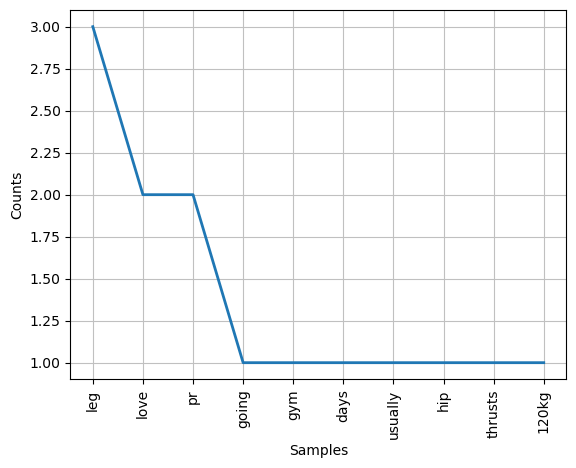

In [2]:
#1.1
s_cleaned=re.sub(r'[^\w\s]','',s.lower())
print(s_cleaned)
print("\n")

#1.2
words=word_tokenize(s_cleaned)
sentences=sent_tokenize(s)
print("Word tokens are ", words)
print("\n")
print("Sentence tokens are ", sentences)
print("\n")

#1.3
print("\n")
print("using split ", s_cleaned.split())
print("\n")
print("using word tokenize ", word_tokenize(s_cleaned))
print("\n")

#1.4
print("\n")
stop_word=set(stopwords.words('english'))
filtered=[
    word for word in words
    if word not in stop_word
]
print("words after removing stopwords are ", filtered)
print("\n")

#1.5
print("\n")
freq=FreqDist(filtered)
print("word frequencies are ")
print("\n")
for word, frequency in freq.most_common():
    print(word,"-", frequency)
freq.plot(10)

In [3]:
#q2
#2.1
alphabets=re.findall(r'\b[a-zA-Z]+\b',s.lower())
print("alphabet only words are ", alphabets)
print("\n")

#2.2
print("\n")
stop_words=set(stopwords.words('english'))
filtered=[
    word for word in alphabets
    if word not in stop_words
]
print("after stopword removal ", filtered)
print("\n")

#2.3
print("\n")
from nltk.stem import PorterStemmer
ps=PorterStemmer()
stemmed=[ps.stem(word) for word in filtered]
print("stemmed words are ", stemmed)
print("\n")

#2.4
print("\n")
from nltk.stem import WordNetLemmatizer
lemmatizer=WordNetLemmatizer()
lemmatized=[
    lemmatizer.lemmatize(word)
    for word in filtered
]
print("lemmatized words are ", lemmatized)
print("\n")

#2.5
print("\n")
from nltk.corpus import wordnet
lemmatized_verbs=[
    lemmatizer.lemmatize(word, pos=wordnet.VERB)
    for word in filtered
]
print("verb aware lemmatisation is ", lemmatized_verbs)

alphabet only words are  ['i', 'love', 'going', 'to', 'the', 'gym', 'i', 'love', 'leg', 'days', 'i', 'usually', 'do', 'hip', 'thrusts', 'of', 'latest', 'pr', 'deadlifts', 'pr', 'leg', 'curls', 'leg', 'extensions', 'and', 'calf', 'raises', 'i', 'also', 'train', 'upper', 'body', 'regularly', 'to', 'maintain', 'good', 'posture', 'and', 'balance', 'of', 'muscles', 'weight', 'training', 'is', 'really', 'important', 'for', 'women', 'and', 'every', 'woman', 'must', 'engage', 'in', 'it']




after stopword removal  ['love', 'going', 'gym', 'love', 'leg', 'days', 'usually', 'hip', 'thrusts', 'latest', 'pr', 'deadlifts', 'pr', 'leg', 'curls', 'leg', 'extensions', 'calf', 'raises', 'also', 'train', 'upper', 'body', 'regularly', 'maintain', 'good', 'posture', 'balance', 'muscles', 'weight', 'training', 'really', 'important', 'women', 'every', 'woman', 'must', 'engage']




stemmed words are  ['love', 'go', 'gym', 'love', 'leg', 'day', 'usual', 'hip', 'thrust', 'latest', 'pr', 'deadlift', 'pr', 'le

In [4]:
#q3
t1="PM Modi to visit to Canada on December 11 and 12"
t2="Marital dispute laws pushing couples towards live-ins? Maharashtra UCC panel asks public"
t3="Prahaar movie review: Rajkummar Rao brings dogged sincerity to Ajmal Kasab trial"
texts=[t1,t2,t3]

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import pandas as pd

#3.1
cv=CountVectorizer()
bow_mat=cv.fit_transform(texts)
bow_df=pd.DataFrame(
    bow_mat.toarray(), columns=cv.get_feature_names_out(), index=["Text 1", "Text 2", "Text 3"]
)
print("bag of words ", bow_df)
print("\n")

#3.2
print("\n")
tfidf=TfidfVectorizer()
tfidf_mat=tfidf.fit_transform(texts)
tfidf_df=pd.DataFrame(
    tfidf_mat.toarray(), columns=tfidf.get_feature_names_out(), index=["Text 1","Text 2", "Text 3"]
)
print("tf idf scores are ", tfidf_df.round(3))
print("\n")

#3.3
print("\n")
feature_name=tfidf.get_feature_names_out()
for i, text in enumerate(texts):
    scores=tfidf_mat[i].toarray().flatten()
    top_indices=scores.argsort()[::-1][:3]

    print(f"\n text {i+1}: {text}")
    print("top 3 keywords ")
    for idx in top_indices:
        print(feature_name[idx], round(scores[idx],3))

bag of words          11  12  ajmal  and  asks  brings  canada  couples  december  dispute  \
Text 1   1   1      0    1     0       0       1        0         1        0   
Text 2   0   0      0    0     1       0       0        1         0        1   
Text 3   0   0      1    0     0       1       0        0         0        0   

        ...  pushing  rajkummar  rao  review  sincerity  to  towards  trial  \
Text 1  ...        0          0    0       0          0   2        0      0   
Text 2  ...        1          0    0       0          0   0        1      0   
Text 3  ...        0          1    1       1          1   1        0      1   

        ucc  visit  
Text 1    0      1  
Text 2    1      0  
Text 3    0      0  

[3 rows x 34 columns]




tf idf scores are             11     12  ajmal    and   asks  brings  canada  couples  december  \
Text 1  0.297  0.297  0.000  0.297  0.000   0.000   0.297    0.000     0.297   
Text 2  0.000  0.000  0.000  0.000  0.277   0.000   0.000 

In [5]:
#q4
text1 = """
Artificial intelligence enables machines to learn from data.
Machine learning helps computers recognize patterns.
AI systems support prediction, automation, and decision making.
Deep learning uses neural networks to solve complex problems.
AI is widely used in healthcare, education, and robotics.
"""

text2 = """
Blockchain is a distributed ledger that stores transactions securely.
It connects blocks using cryptographic techniques.
Blockchain supports transparency and decentralized applications.
Smart contracts execute agreements automatically.
Blockchain is widely used in cryptocurrency and supply chain management.
"""
#4.1
stop_words=set(stopwords.words('english'))
def preprocess(text):
    text=text.lower()
    text=re.sub(r'[^a-z\s]','',text)
    tokens=word_tokenize(text)
    tokens=[
        word for word in tokens
        if word not in stop_words
    ]
    return tokens
    
tokens1=preprocess(text1)
tokens2=preprocess(text2)
print("AI tokens are ", tokens1)
print("\nBlockchain tokens are ", tokens2)
print("\n")

#4.2.1
print("\n")
set1=set(tokens1)
set2=set(tokens2)
intersection=set1.intersection(set2)
union=set1.union(set2)
jac=len(intersection)/len(union)
print("common words are ",intersection)
print("jaccard similarity is ", round(jac,3))
print("\n")

#4.2.2
print("\n")
from sklearn.metrics.pairwise import cosine_similarity

preprocessed_texts=[
    " ".join(tokens1)," ".join(tokens2)
]
vectorizer=TfidfVectorizer()
tfidf_mat=vectorizer.fit_transform(preprocessed_texts)
cosine_score=cosine_similarity(tfidf_mat[0:1], tfidf_mat[1:2])[0][0]
print("cosine similarity is ", round(cosine_score,3))


AI tokens are  ['artificial', 'intelligence', 'enables', 'machines', 'learn', 'data', 'machine', 'learning', 'helps', 'computers', 'recognize', 'patterns', 'ai', 'systems', 'support', 'prediction', 'automation', 'decision', 'making', 'deep', 'learning', 'uses', 'neural', 'networks', 'solve', 'complex', 'problems', 'ai', 'widely', 'used', 'healthcare', 'education', 'robotics']

Blockchain tokens are  ['blockchain', 'distributed', 'ledger', 'stores', 'transactions', 'securely', 'connects', 'blocks', 'using', 'cryptographic', 'techniques', 'blockchain', 'supports', 'transparency', 'decentralized', 'applications', 'smart', 'contracts', 'execute', 'agreements', 'automatically', 'blockchain', 'widely', 'used', 'cryptocurrency', 'supply', 'chain', 'management']




common words are  {'widely', 'used'}
jaccard similarity is  0.036




cosine similarity is  0.029


Review: This phone has an excellent camera and amazing battery life.
Polarity: 0.8
Subjectivity: 0.95
Sentiment: Positive
------------------------------------------------------------
Review: The product is fantastic and very easy to use.
Polarity: 0.48
Subjectivity: 0.95
Sentiment: Positive
------------------------------------------------------------
Review: I love this laptop because it is fast and reliable and light weight.
Polarity: 0.37
Subjectivity: 0.63
Sentiment: Positive
------------------------------------------------------------
Review: The quality is terrible and the battery drains quickly and it is very heavy.
Polarity: -0.31
Subjectivity: 0.72
Sentiment: Negative
------------------------------------------------------------
Review: Very disappointing product. It stopped working in two days.
Polarity: -0.78
Subjectivity: 0.91
Sentiment: Negative
------------------------------------------------------------
Review: The service was poor and the product was damaged.
Polarity: -0

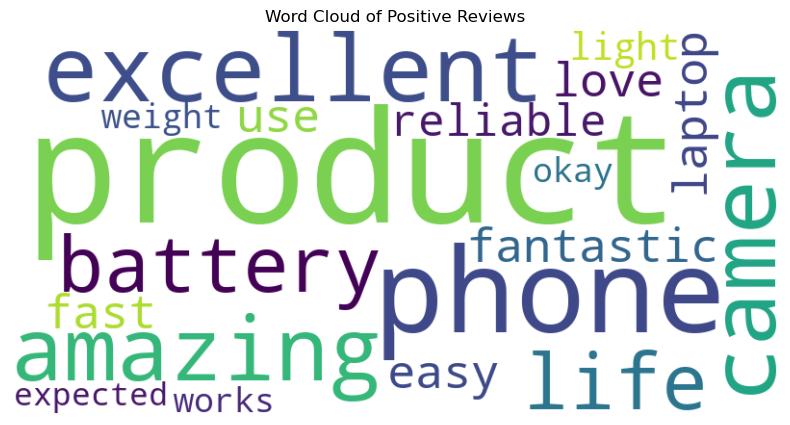

In [6]:
#q5
!pip install textblob wordcloud matplotlib
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

reviews = [
    "This phone has an excellent camera and amazing battery life.",
    "The product is fantastic and very easy to use.",
    "I love this laptop because it is fast and reliable and light weight.",
    "The quality is terrible and the battery drains quickly and it is very heavy.",
    "Very disappointing product. It stopped working in two days.",
    "The service was poor and the product was damaged.",
    "The product is okay and works as expected.",
    "It is an average product with normal features."
]

positive_reviews = []
#5.1
for review in reviews:
    analysis=TextBlob(review)
    polarity=analysis.sentiment.polarity
    subjectivity=analysis.sentiment.subjectivity

    if polarity > 0:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("Review:", review)
    print("Polarity:", round(polarity, 2))
    print("Subjectivity:", round(subjectivity, 2))
    print("Sentiment:", sentiment)
    print("-" * 60)
#5.2
positive_text = " ".join(positive_reviews)

#5.3
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(positive_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Positive Reviews")
plt.show()


In [8]:
#q6
!pip install tensorflow

import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

text = """
Artificial intelligence is changing the world.
Machines can learn from data and solve complex problems.
Deep learning is a branch of machine learning.
Neural networks learn patterns from examples.
Natural language processing helps computers understand human language.
Recurrent neural networks process sequential data.
LSTM networks remember important information for a long time.
Text generation uses language patterns to predict the next word.
Training data helps a model learn vocabulary and grammar.
More data can improve the quality of generated text.
Artificial intelligence is useful in education, healthcare, and business.
Machine learning continues to create exciting opportunities.
"""

#6.1
tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1
print("Vocabulary size:", total_words)

input_sequences = []

for line in text.lower().split("."):
    line = line.strip()

    if not line:
        continue

    token_list = tokenizer.texts_to_sequences([line])[0]

    for i in range(1, len(token_list)):
        input_sequences.append(token_list[:i + 1])

max_len = max(len(seq) for seq in input_sequences)

input_sequences = pad_sequences(
    input_sequences,
    maxlen=max_len,
    padding="pre"
)

X = input_sequences[:, :-1]
y = input_sequences[:, -1]

model = Sequential([
    Embedding(total_words, 32, input_length=max_len - 1),
    LSTM(64),
    Dense(total_words, activation="softmax")
])

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

model.summary()

model.fit(X, y, epochs=200, verbose=0)
print("Model training completed!")

#6.2
def generate_text(seed_text, next_words=10):
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences(
            [seed_text.lower()]
        )[0]

        token_list = pad_sequences(
            [token_list],
            maxlen=max_len - 1,
            padding="pre"
        )

        predicted = model.predict(token_list, verbose=0)
        predicted_id = int(np.argmax(predicted, axis=1)[0])

        output_word = None

        for word, index in tokenizer.word_index.items():
            if index == predicted_id:
                output_word = word
                break

        if output_word is None:
            break

        seed_text += " " + output_word

    return seed_text

#6.3
print("\nGenerated Text:")
print(generate_text("artificial intelligence", 10))
print(generate_text("machine learning", 10))
print(generate_text("neural networks", 10))


Vocabulary size: 67


C:\Users\DELL\anaconda3\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)              │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Model training completed!

Generated Text:
artificial intelligence is changing the world world next text text word word
machine learning continues to create exciting opportunities opportunities word word word problems
neural networks learn patterns from examples examples long long time problems problems
